<a href="https://colab.research.google.com/github/eliseiuoi/MMA3001-smart-building-sensor-reconstruction/blob/main/02_reconstruction_validation_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reconstruction of Missing Environmental Sensor Measurements

## Aim

This notebook evaluates computational methods for reconstructing missing temperature measurements from the Monash Smart Infrastructure Lab dataset.

Temperature is initially used as the target variable. Known temperature measurements are artificially removed and then reconstructed so that predicted values can be compared with the original measurements.

Linear interpolation is first evaluated as a simple numerical baseline. Machine-learning regression methods taught in MMA3001, including linear regression and decision tree regression, are then evaluated using the same validation framework.

The performance of each method will be compared using quantitative error metrics such as Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).


## Project Development Strategy

This project follows an iterative computational workflow. A simple numerical
method is first established as a baseline, after which progressively more
complex regression approaches are evaluated.

Each development step is assessed using the same withheld temperature
measurements and quantitative error metrics where possible. Results from each
experiment are used to determine the next modelling decision rather than
selecting methods based on preference alone.

The overall development flow is:

1. Audit and understand the environmental sensor data.
2. Establish linear interpolation as a numerical reconstruction baseline.
3. Evaluate linear regression using environmental predictor variables.
4. Evaluate decision tree regression as a nonlinear alternative.
5. Investigate whether additional features, including CO2 concentration and
   temporal information, improve reconstruction accuracy.
6. Evaluate sensitivity to the number and duration of consecutive missing
   temperature measurements.
7. Compare accuracy, robustness, computational cost and implementation
   complexity before selecting the final recommended approach.

# 1. Data Preparation:

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from google.colab import files

uploaded = files.upload()

Saving Env_data_MSI_Lab - 30-07-2025_19-12-2025.csv to Env_data_MSI_Lab - 30-07-2025_19-12-2025.csv


In [5]:
import pandas as pd

df = pd.read_csv("Env_data_MSI_Lab - 30-07-2025_19-12-2025.csv")

df["time"] = pd.to_datetime(df["time"])

df = df.sort_values("time").reset_index(drop=True)

display(df.head())

,time,Pressure (mb),Temperature (°C),Humidity (RH %),CO2 (ppm),LVOC (ppb),Formaldehyde (µg/m3)
0,2025-07-30 10:39:23,1012,24.8,32,612.0,0,4.0
1,2025-07-30 10:46:38,1012,24.8,32,630.0,0,NaN
2,2025-07-30 11:01:12,1012,24.8,32,626.0,0,4.0
3,2025-07-30 11:05:57,1012,24.8,32,624.0,0,4.0
4,2025-07-30 11:39:22,1012,25.0,31,584.0,0,4.0


In [6]:
#Extract only temparature:
temperature_data = df[["time", "Temperature (°C)"]].copy()

display(temperature_data.head())

,time,Temperature (°C)
0,2025-07-30 10:39:23,24.8
1,2025-07-30 10:46:38,24.8
2,2025-07-30 11:01:12,24.8
3,2025-07-30 11:05:57,24.8
4,2025-07-30 11:39:22,25.0


In [7]:

#Check whether temparature itself contains missing measurements:

print(temperature_data.isna().sum())


#Check duplicate timestamps:
print(
    "Duplicate timestamps:",
    temperature_data["time"].duplicated().sum()
)

time                0
Temperature (°C)    0
dtype: int64
Duplicate timestamps: 0


# Model development/initial validation

# 2. Baseline Method: Linear Interpolation

## 2.1 Single-Point Demonstration

In [8]:
#Select one real measurement:

#find approximately the middle measurement.
test_index = len(temperature_data) // 2


#We're choosing a point from the middle rather than the beginning or end because linear interpolation needs measurements before and after the missing point.

temperature_data.loc[
    test_index - 2:test_index + 2
]



,time,Temperature (°C)
2478,2025-09-16 14:12:04,24.8
2479,2025-09-16 14:21:51,24.5
2480,2025-09-16 14:36:59,24.3
2481,2025-09-16 14:42:12,24.0
2482,2025-09-16 14:51:34,24.3


In [9]:
#Store the actual value:
actual_temperature = temperature_data.loc[
    test_index,
    "Temperature (°C)"
]

test_time = temperature_data.loc[
    test_index,
    "time"
]

print("Test time:", test_time)
print("Actual temperature:", actual_temperature, "°C")


Test time: 2025-09-16 14:36:59
Actual temperature: 24.3 °C


In [10]:
#Artificially remove it:

#Make a copy:
test_data = temperature_data.copy()

#Remove the measurement:
test_data.loc[
    test_index,
    "Temperature (°C)"
] = np.nan


#Display the area around it:
display(
    test_data.loc[test_index - 2:test_index + 2]
)


,time,Temperature (°C)
2478,2025-09-16 14:12:04,24.8
2479,2025-09-16 14:21:51,24.5
2480,2025-09-16 14:36:59,NaN
2481,2025-09-16 14:42:12,24.0
2482,2025-09-16 14:51:34,24.3


In [11]:
#Do linear interpolation manually:

t1 = temperature_data.loc[test_index - 1, "time"]
T1 = temperature_data.loc[test_index - 1, "Temperature (°C)"]

t = temperature_data.loc[test_index, "time"]

t2 = temperature_data.loc[test_index + 1, "time"]
T2 = temperature_data.loc[test_index + 1, "Temperature (°C)"]

print("Previous:", t1, T1)
print("Missing point time:", t)
print("Next:", t2, T2)

Previous: 2025-09-16 14:21:51 24.5
Missing point time: 2025-09-16 14:36:59
Next: 2025-09-16 14:42:12 24.0


In [12]:
predicted_temperature = T1 + (
    (t - t1) / (t2 - t1)
) * (T2 - T1)

print(
    "Predicted temperature:",
    predicted_temperature,
    "°C"
)

print(
    "Actual temperature:",
    actual_temperature,
    "°C"
)

Predicted temperature: 24.128173628173627 °C
Actual temperature: 24.3 °C


In [13]:
#Calculate the error:

absolute_error = abs(
    actual_temperature - predicted_temperature
)

print(
    "Absolute error:",
    absolute_error,
    "°C"
)


Absolute error: 0.1718263718263735 °C


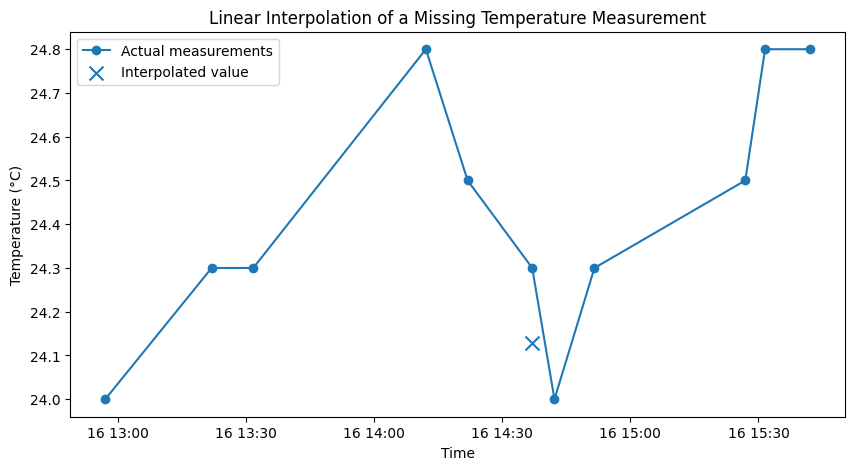

In [14]:
#Visualise what happened:
plot_data = temperature_data.loc[
    test_index - 5:test_index + 5
]

plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["time"],
    plot_data["Temperature (°C)"],
    marker="o",
    label="Actual measurements"
)

plt.scatter(
    test_time,
    predicted_temperature,
    marker="x",
    s=100,
    label="Interpolated value"
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Linear Interpolation of a Missing Temperature Measurement")
plt.legend()

plt.show()

## Initial Linear Interpolation Test

A known temperature measurement was artificially removed from the dataset
to simulate a sensor measurement failure.

Linear interpolation was then used to reconstruct the missing measurement
using the measurements immediately before and after the removed point.

Because the original value was known, the reconstructed value could be
directly compared with the true measurement. This provides a simple
validation of the interpolation method.

Now repeat the experiment many times. Instead of hiding one value, we'll hide many known values and see how the method performs overall.

Choose every 20th measurement, while avoiding the beginning and end.

## 2.2 Multi-Point Validation:

In [15]:
validation_indices = np.arange(
    10,
    len(temperature_data) - 10,
    20
)

print(
    "Number of validation points:",
    len(validation_indices)
)

Number of validation points: 247


In [16]:
#Hide all those values:
validation_data = temperature_data.copy()

actual_values = validation_data.loc[
    validation_indices,
    "Temperature (°C)"
].copy()

validation_data.loc[
    validation_indices,
    "Temperature (°C)"
] = np.nan

In [17]:
#Let pandas perform time-based interpolation:
validation_data = validation_data.set_index("time")

validation_times = temperature_data.loc[
    validation_indices,
    "time"
]

validation_data["linear_interpolated"] = (
    validation_data["Temperature (°C)"]
    .interpolate(method="time")
)

display(
    validation_data.loc[
        validation_times,
        ["Temperature (°C)", "linear_interpolated"]
    ].head()
)

,Temperature (°C),linear_interpolated
time,,
2025-07-30 14:56:33,NaN,25.654945
2025-07-30 20:29:08,NaN,24.672085
2025-07-31 01:16:05,NaN,23.800000
2025-07-31 10:04:09,NaN,23.855658
2025-07-31 14:16:51,NaN,24.000000


In [18]:
#Extract predictions:
validation_times = temperature_data.loc[
    validation_indices,
    "time"
]

predicted_values = validation_data.loc[
    validation_times,
    "linear_interpolated"
].to_numpy()

actual_values = actual_values.to_numpy()

## 2.3 Baseline Results:

In [19]:
#Calcualte MAE and RMSE:

mae = np.mean(
    np.abs(actual_values - predicted_values)
)

rmse = np.sqrt(
    np.mean(
        (actual_values - predicted_values) ** 2
    )
)

print("MAE:", mae, "°C")
print("RMSE:", rmse, "°C")

MAE: 0.12425081632736212 °C
RMSE: 0.2214190921287753 °C


## Linear Interpolation Baseline Results

Linear interpolation achieved an MAE of approximately 0.124 °C and an RMSE
of approximately 0.221 °C when reconstructing artificially removed
temperature measurements.

The RMSE is higher than the MAE, indicating that some reconstructed
measurements have larger errors than the typical prediction error.

These results establish a numerical baseline for comparison with
machine-learning regression methods evaluated using the same withheld
temperature measurements.

# 3. Machine-Learning Regression Methods

The next stage investigates whether regression models can reconstruct missing
temperature measurements using other environmental sensor variables.

The same withheld temperature measurements used to evaluate linear
interpolation will be retained for the regression models. This allows the
methods to be compared using the same ground-truth measurements and the same
error metrics.

The first machine-learning model evaluated is linear regression, followed by
decision tree regression.

### Assumption

This analysis assumes that the temperature measurement is missing while other
environmental variables remain available. Therefore, it represents a missing
temperature channel or corrupted temperature measurement rather than a
complete environmental sensor outage.

## 3.1.  Feature and Target Definition (*X* and *y*):
Temperature is selected as the regression target.

The initial linear regression model uses pressure and humidity as predictor
features. These variables are available throughout the dataset and provide a
simple starting model before investigating additional features.

- **Features (X):** Pressure and Humidity
- **Target (y):** Temperature

In [20]:
# Define predictor features and target variable

features = [
    "Pressure (mb)",
    "Humidity (RH %)"
]

target = "Temperature (°C)"

X = df[features].copy()
y = df[target].copy()

display(X.head())
display(y.head())

,Pressure (mb),Humidity (RH %)
0,1012,32
1,1012,32
2,1012,32
3,1012,32
4,1012,31


,Temperature (°C)
0,24.8
1,24.8
2,24.8
3,24.8
4,25.0


## 3.2 Use the SAME validation points

In [21]:
# Use the same validation points as the interpolation experiment

validation_mask = df.index.isin(validation_indices)

X_train = X.loc[~validation_mask] #mean NOT validation_mask, flips every Boolean
y_train = y.loc[~validation_mask]

X_validation = X.loc[validation_mask]
y_validation = y.loc[validation_mask]
# We're not literally replacing the validation temparature with NaN this time.
# Instead, we simply exclude them from model training (y_validation) only
# because we need the true temparatures later to assess the prediction.


print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))

Training samples: 4713
Validation samples: 247


## 3.3 Check the split


In [22]:
print("Total measurements:", len(df))

print(
    "Training + validation:",
    len(X_train) + len(X_validation)
)

display(X_validation.head())
display(y_validation.head())

Total measurements: 4960
Training + validation: 4960


,Pressure (mb),Humidity (RH %)
10,1012,32
30,1015,33
50,1017,32
70,1020,33
90,1018,33


,Temperature (°C)
10,25.5
30,24.5
50,23.8
70,23.5
90,23.8


## 3.4 Train Linear Regression:  


In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
linear_regression_model = LinearRegression()

linear_regression_model.fit(
    X_train,
    y_train
)

LinearRegression()

## 3.5 Look at what the model learned

In [25]:
print(
    "Intercept:",
    linear_regression_model.intercept_
)

coefficient_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_regression_model.coef_
})

display(coefficient_table)

Intercept: 42.04542510272555


,Feature,Coefficient
0,Pressure (mb),-0.016545
1,Humidity (RH %),-0.018444


## 3.6 Predict the hidden temparatures:  


In [26]:
linear_regression_predictions = (
    linear_regression_model.predict(X_validation)
)

In [27]:
# Create a table:

linear_regression_results = pd.DataFrame({
    "Actual Temperature (°C)": y_validation.to_numpy(),
    "Predicted Temperature (°C)": linear_regression_predictions
})

display(linear_regression_results.head(10))

,Actual Temperature (°C),Predicted Temperature (°C)
0,25.5,24.711895
1,24.5,24.643817
2,23.8,24.629171
3,23.5,24.561093
4,23.8,24.594182
5,24.0,24.540750
6,24.3,24.577637
7,24.0,24.577637
8,25.3,24.542649
9,24.0,24.540750


## 3.7 Calculate MAE and RMSE

In [28]:
linear_regression_mae = np.mean(
    np.abs(
        y_validation.to_numpy()
        - linear_regression_predictions
    )
)

linear_regression_rmse = np.sqrt(
    np.mean(
        (
            y_validation.to_numpy()
            - linear_regression_predictions
        ) ** 2
    )
)

print(
    "Linear Regression MAE:",
    linear_regression_mae,
    "°C"
)

print(
    "Linear Regression RMSE:",
    linear_regression_rmse,
    "°C"
)

Linear Regression MAE: 0.6920958353390523 °C
Linear Regression RMSE: 0.844096538778313 °C


## 3.8 Make the first method comparison table

In [29]:
method_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse
    ]
})

display(method_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097


## 3.9 Calculate residuals:





In [30]:
linear_regression_residuals = (
    y_validation.to_numpy()
    - linear_regression_predictions
)

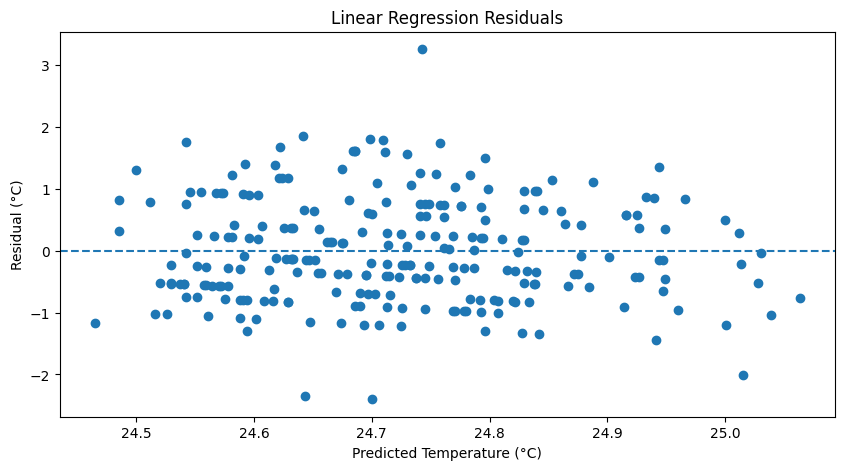

In [31]:
plt.figure(figsize=(10, 5))

plt.scatter(
    linear_regression_predictions,
    linear_regression_residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Linear Regression Residuals")

plt.show()

### Initial Method Comparison

Linear interpolation achieved substantially lower reconstruction errors than
the initial linear regression model.

- Linear interpolation: MAE = 0.124 °C, RMSE = 0.221 °C
- Linear regression: MAE = 0.692 °C, RMSE = 0.844 °C

The linear regression model used pressure and humidity as predictor features,
whereas linear interpolation used neighbouring temperature measurements and
their timestamps.

The poorer performance of linear regression suggests that pressure and
humidity alone do not provide sufficient information for a simple linear
model to accurately reconstruct temperature. The residual plot also shows
several relatively large prediction errors.

These results do not establish that regression methods are unsuitable in
general. A more flexible nonlinear regression model will next be evaluated
using the same predictor features and validation points.



# 4. Decision Tree Regression

Decision tree regression is evaluated as a nonlinear alternative to linear
regression.

The model uses the same predictor features and validation points as the
linear regression model:

- Pressure
- Humidity

The target remains temperature.

Unlike linear regression, a decision tree can learn nonlinear relationships
by repeatedly splitting the feature space using threshold rules.


In [32]:
from sklearn.tree import DecisionTreeRegressor

## 4.1 Create an initial tree

In [33]:
decision_tree_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

## 4.2 Train it

In [34]:
decision_tree_model.fit(
    X_train,
    y_train
)

DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)

## 4.3 Predict the validation temperatures

In [35]:
decision_tree_predictions = (
    decision_tree_model.predict(X_validation)
)

In [36]:
#Inspect some predictions:

decision_tree_results = pd.DataFrame({
    "Actual Temperature (°C)": y_validation.to_numpy(),
    "Predicted Temperature (°C)": decision_tree_predictions
})

display(decision_tree_results.head(10))

,Actual Temperature (°C),Predicted Temperature (°C)
0,25.5,24.524906
1,24.5,24.746014
2,23.8,24.746014
3,23.5,24.555390
4,23.8,24.555390
5,24.0,24.248421
6,24.3,24.555390
7,24.0,24.555390
8,25.3,24.248421
9,24.0,24.248421


## 4.4 Calculate MAE and RMSE

In [37]:
decision_tree_mae = np.mean(
    np.abs(
        y_validation.to_numpy()
        - decision_tree_predictions
    )
)

decision_tree_rmse = np.sqrt(
    np.mean(
        (
            y_validation.to_numpy()
            - decision_tree_predictions
        ) ** 2
    )
)

print(
    "Decision Tree MAE:",
    decision_tree_mae,
    "°C"
)

print(
    "Decision Tree RMSE:",
    decision_tree_rmse,
    "°C"
)

Decision Tree MAE: 0.6807796486562573 °C
Decision Tree RMSE: 0.838483252425696 °C


## 4.5 Update your comparision table

In [38]:
method_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Decision Tree Regression"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae,
        decision_tree_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse,
        decision_tree_rmse
    ]
})

display(method_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097
2,Decision Tree Regression,0.680780,0.838483


## 4.6 Visualise the tree:

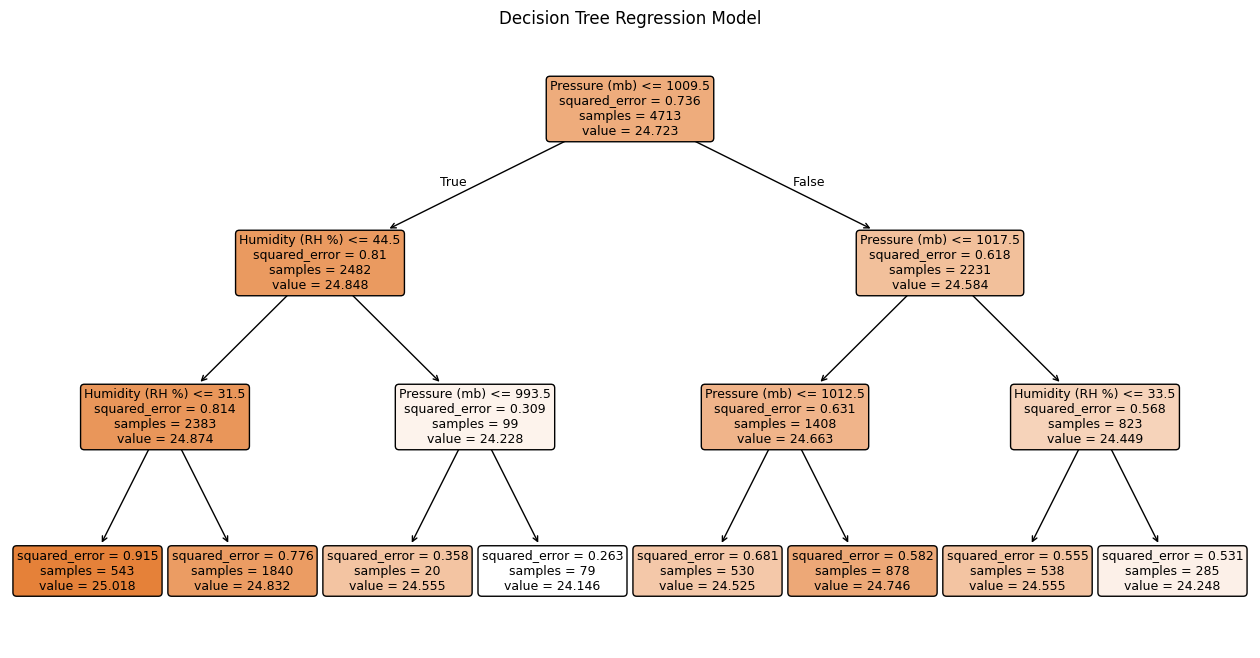

In [39]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    decision_tree_model,
    feature_names=features,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Regression Model")

plt.show()

## 4.7 Residual plot

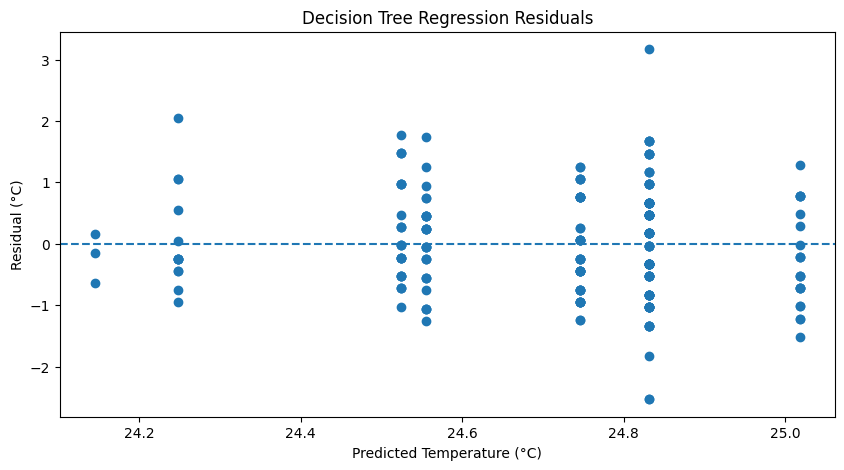

In [40]:
decision_tree_residuals = (
    y_validation.to_numpy()
    - decision_tree_predictions
)

plt.figure(figsize=(10, 5))

plt.scatter(
    decision_tree_predictions,
    decision_tree_residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Residual (°C)")
plt.title("Decision Tree Regression Residuals")

plt.show()

### Initial Decision Tree Results

Decision tree regression produced an MAE of approximately 0.681 °C and an
RMSE of approximately 0.838 °C.

This represents only a small improvement over the initial linear regression
model, which achieved an MAE of 0.692 °C and an RMSE of 0.844 °C.

Although the decision tree can represent nonlinear relationships between
pressure, humidity and temperature, the improvement is limited. This suggests
that model flexibility alone is not sufficient and that pressure and humidity
may not contain enough information to accurately reconstruct temperature.

The vertical groups visible in the residual plot occur because a decision tree
produces piecewise-constant predictions. Observations falling within the same
terminal leaf receive the same predicted temperature.

Linear interpolation remains substantially more accurate under the current
validation conditions.

# 5. Feature Expansion: Adding CO₂


The initial regression models used pressure and humidity to predict temperature.
Both linear regression and decision tree regression performed substantially
worse than the linear interpolation baseline.

The next experiment investigates whether adding CO₂ concentration provides
additional information that improves temperature reconstruction.

The model structure, validation points and evaluation metrics are kept
consistent so that the effect of adding CO₂ can be assessed.

In [41]:
#Define the new feature set:
features_co2 = [
    "Pressure (mb)",
    "Humidity (RH %)",
    "CO2 (ppm)"
]

X_co2 = df[features_co2].copy()
y_co2 = df["Temperature (°C)"].copy()

In [42]:
# Check number of missing readings:
print(X_co2.isna().sum())

Pressure (mb)      0
Humidity (RH %)    0
CO2 (ppm)          2
dtype: int64


In [43]:
# Check whether any of the validation points have missing CO2:
validation_mask = df.index.isin(validation_indices)

print(
    "Validation rows with missing features:",
    X_co2.loc[validation_mask].isna().any(axis=1).sum()
)

Validation rows with missing features: 0


In [44]:
# Remove training rows with missing feature values
training_mask_co2 = (~validation_mask) & X_co2.notna().all(axis=1)

X_train_co2 = X_co2.loc[training_mask_co2]
y_train_co2 = y_co2.loc[training_mask_co2]

# Keep exactly the same validation points
X_validation_co2 = X_co2.loc[validation_mask]
y_validation_co2 = y_co2.loc[validation_mask]

print("Training samples:", len(X_train_co2))
print("Validation samples:", len(X_validation_co2))

Training samples: 4711
Validation samples: 247


In [45]:
# Retrain Linear Regression:

linear_regression_co2 = LinearRegression()

linear_regression_co2.fit(
    X_train_co2,
    y_train_co2
)

linear_regression_co2_predictions = (
    linear_regression_co2.predict(X_validation_co2)
)

In [46]:
# Calculate its errors:

linear_regression_co2_mae = np.mean(
    np.abs(
        y_validation_co2.to_numpy()
        - linear_regression_co2_predictions
    )
)

linear_regression_co2_rmse = np.sqrt(
    np.mean(
        (
            y_validation_co2.to_numpy()
            - linear_regression_co2_predictions
        ) ** 2
    )
)

print("Linear Regression + CO2 MAE:",
      linear_regression_co2_mae, "°C")

print("Linear Regression + CO2 RMSE:",
      linear_regression_co2_rmse, "°C")


Linear Regression + CO2 MAE: 0.6747935145467142 °C
Linear Regression + CO2 RMSE: 0.8351675072912422 °C


In [47]:
# Repeat for the Decision Tree:

decision_tree_co2 = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

decision_tree_co2.fit(
    X_train_co2,
    y_train_co2
)

decision_tree_co2_predictions = (
    decision_tree_co2.predict(X_validation_co2)
)

In [48]:
# Calculate its errors:

decision_tree_co2_mae = np.mean(
    np.abs(
        y_validation_co2.to_numpy()
        - decision_tree_co2_predictions
    )
)

decision_tree_co2_rmse = np.sqrt(
    np.mean(
        (
            y_validation_co2.to_numpy()
            - decision_tree_co2_predictions
        ) ** 2
    )
)

print("Decision Tree + CO2 MAE:",
      decision_tree_co2_mae, "°C")

print("Decision Tree + CO2 RMSE:",
      decision_tree_co2_rmse, "°C")

Decision Tree + CO2 MAE: 0.5922337439645724 °C
Decision Tree + CO2 RMSE: 0.76486490624837 °C


In [49]:
# Comparision table:

feature_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Linear Regression + CO2",
        "Decision Tree Regression",
        "Decision Tree Regression + CO2"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae,
        linear_regression_co2_mae,
        decision_tree_mae,
        decision_tree_co2_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse,
        linear_regression_co2_rmse,
        decision_tree_rmse,
        decision_tree_co2_rmse
    ]
})

display(feature_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097
2,Linear Regression + CO2,0.674794,0.835168
3,Decision Tree Regression,0.680780,0.838483
4,Decision Tree Regression + CO2,0.592234,0.764865


### Effect of Adding CO₂

Adding CO₂ concentration produced a small improvement in the linear regression
model and a more noticeable improvement in the decision tree regression model.

Linear regression improved from an MAE of 0.692 °C to 0.675 °C, while the
decision tree improved from an MAE of 0.681 °C to 0.592 °C.

This suggests that CO₂ contains additional information relevant to temperature
reconstruction, particularly when nonlinear relationships can be represented.

However, linear interpolation remains substantially more accurate than both
regression approaches under the current validation conditions.

# 6. Feature Expansion: Temporal Information

Temperature may vary systematically with time due to daily building operation,
HVAC behaviour, occupancy and environmental conditions.

The next experiment therefore introduces temporal features in addition to
pressure, humidity and CO₂.

Hour-of-day information is represented using cyclical sine and cosine features
so that times near midnight remain close to one another numerically.

In [50]:
# Extract hour as a decimal value

df["hour_decimal"] = (
    df["time"].dt.hour
    + df["time"].dt.minute / 60
    + df["time"].dt.second / 3600
)

In [51]:
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour_decimal"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour_decimal"] / 24
)

# make 23:00 and 00:00 close together

In [52]:
features_time = [
    "Pressure (mb)",
    "Humidity (RH %)",
    "CO2 (ppm)",
    "hour_sin",
    "hour_cos"
]

X_time = df[features_time].copy()

y_time = df["Temperature (°C)"].copy()

In [53]:
# check missing values:

print(X_time.isna().sum())

Pressure (mb)      0
Humidity (RH %)    0
CO2 (ppm)          2
hour_sin           0
hour_cos           0
dtype: int64


In [54]:
# check validation rule:

validation_mask = df.index.isin(validation_indices)

print(
    "Validation rows with missing features:",
    X_time.loc[validation_mask].isna().any(axis=1).sum()
)


Validation rows with missing features: 0


In [55]:
training_mask_time = (
    (~validation_mask)
    & X_time.notna().all(axis=1)
)

X_train_time = X_time.loc[training_mask_time]
y_train_time = y_time.loc[training_mask_time]

X_validation_time = X_time.loc[validation_mask]
y_validation_time = y_time.loc[validation_mask]

print("Training samples:", len(X_train_time))
print("Validation samples:", len(X_validation_time))

Training samples: 4711
Validation samples: 247


In [56]:
# Retrain Linear Regression:

linear_regression_time = LinearRegression()

linear_regression_time.fit(
    X_train_time,
    y_train_time
)

linear_regression_time_predictions = (
    linear_regression_time.predict(
        X_validation_time
    )
)

In [57]:
# Calculate errors:

linear_regression_time_mae = np.mean(
    np.abs(
        y_validation_time.to_numpy()
        - linear_regression_time_predictions
    )
)

linear_regression_time_rmse = np.sqrt(
    np.mean(
        (
            y_validation_time.to_numpy()
            - linear_regression_time_predictions
        ) ** 2
    )
)

print(
    "Linear Regression + CO2 + Time MAE:",
    linear_regression_time_mae
)


print(
    "Linear Regression + CO2 + Time RMSE:",
    linear_regression_time_rmse
)

Linear Regression + CO2 + Time MAE: 0.6128791598177458
Linear Regression + CO2 + Time RMSE: 0.7786607585674965


In [58]:
# Do the same for Decision Tree:

decision_tree_time = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=20,
    random_state=42
)

decision_tree_time.fit(
    X_train_time,
    y_train_time
)

decision_tree_time_predictions = (
    decision_tree_time.predict(
        X_validation_time
    )
)

In [59]:
decision_tree_time_mae = np.mean(
    np.abs(
        y_validation_time.to_numpy()
        - decision_tree_time_predictions
    )
)

decision_tree_time_rmse = np.sqrt(
    np.mean(
        (
            y_validation_time.to_numpy()
            - decision_tree_time_predictions
        ) ** 2
    )
)

print(
    "Decision Tree + CO2 + Time MAE:",
    decision_tree_time_mae
)

print(
    "Decision Tree + CO2 + Time RMSE:",
    decision_tree_time_rmse
)

Decision Tree + CO2 + Time MAE: 0.5765998435013115
Decision Tree + CO2 + Time RMSE: 0.742592941182237


In [60]:
# Update the table:
time_feature_comparison = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Linear Regression + CO2",
        "Linear Regression + CO2 + Time",
        "Decision Tree",
        "Decision Tree + CO2",
        "Decision Tree + CO2 + Time"
    ],

    "MAE (°C)": [
        mae,
        linear_regression_mae,
        linear_regression_co2_mae,
        linear_regression_time_mae,
        decision_tree_mae,
        decision_tree_co2_mae,
        decision_tree_time_mae
    ],

    "RMSE (°C)": [
        rmse,
        linear_regression_rmse,
        linear_regression_co2_rmse,
        linear_regression_time_rmse,
        decision_tree_rmse,
        decision_tree_co2_rmse,
        decision_tree_time_rmse
    ]
})

display(time_feature_comparison)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.124251,0.221419
1,Linear Regression,0.692096,0.844097
2,Linear Regression + CO2,0.674794,0.835168
3,Linear Regression + CO2 + Time,0.612879,0.778661
4,Decision Tree,0.680780,0.838483
5,Decision Tree + CO2,0.592234,0.764865
6,Decision Tree + CO2 + Time,0.576600,0.742593


# Robustness/sensitivity validation:

# 7. Sensitivity to Missing-Gap Size

The previous experiments evaluated reconstruction performance primarily using
isolated missing temperature measurements.

However, a real sensor fault may result in several consecutive measurements
being unavailable. The accuracy of a reconstruction method may therefore
depend on the duration of the missing-data interval.

This section investigates how reconstruction performance changes as the number
of consecutive missing temperature measurements increases. For each simulated gap, all temperature measurements within the selected interval are artificially removed and subsequently reconstructed

Three approaches are compared:

- Linear interpolation
- Linear regression using pressure, humidity, CO2 and temporal features
- Decision tree regression using pressure, humidity, CO2 and temporal features

Known temperature measurements are artificially removed so that reconstructed
values can be compared directly with the original measurements.

Performance is evaluated using Mean Absolute Error (MAE) and Root Mean Squared
Error (RMSE).


## 7.1 Experimental Design

Four missing-gap sizes are investigated:

- 1 consecutive missing measurement
- 3 consecutive missing measurements
- 6 consecutive missing measurements
- 12 consecutive missing measurements

For each gap size, 50 starting locations are selected throughout the dataset.

At each location:

1. The original temperature measurements within the gap are retained as ground
   truth.
2. The temperature measurements are artificially removed.
3. Linear interpolation reconstructs the missing temperatures using surrounding
   temperature measurements and their timestamps.
4. Linear regression and decision tree regression reconstruct the same
   temperatures using pressure, humidity, CO2 and temporal features.
5. Predictions are compared with the known original temperatures using MAE and
   RMSE.

The same gap locations are used for all methods to ensure a consistent
comparison.

The actual elapsed time between the known measurements surrounding each gap is
also recorded because the original sensor data are irregularly sampled.

In [61]:
#Define the gap experiment:

gap_sizes = [1, 3, 6, 12]

Given the median sampling interval of roughly 10.6 minutes, these correspond very roughly to increasingly long outages, but because sampling is irregular, we should later report the actual elapsed time, not simply assume each reading is exactly 10 minutes apart.

In [62]:
def evaluate_gap(start_index, gap_size):
    """
    Evaluate reconstruction methods for one artificial temperature gap.

    Parameters
    ----------
    start_index : int
        Index of the first measurement to remove.

    gap_size : int
        Number of consecutive temperature measurements removed.

    Returns
    -------
    list of dict
        MAE and RMSE for each reconstruction method.
    """

    gap_indices = np.arange(
        start_index,
        start_index + gap_size
    )

    # True temperatures that will be hidden
    actual = y_time.loc[gap_indices].to_numpy()

    # Features available during the simulated failure
    gap_features = X_time.loc[gap_indices]

    # Skip gaps containing missing predictor values
    if gap_features.isna().any().any():
        return None

    # --------------------------------------------------
    # 1. Linear interpolation
    # --------------------------------------------------

    interpolation_data = df[
        ["time", "Temperature (°C)"]
    ].copy()

    interpolation_data.loc[
        gap_indices,
        "Temperature (°C)"
    ] = np.nan

    interpolation_series = (
        interpolation_data
        .set_index("time")["Temperature (°C)"]
        .interpolate(method="time")
    )

    gap_times = df.loc[
        gap_indices,
        "time"
    ]

    interpolation_predictions = (
        interpolation_series.loc[gap_times]
        .to_numpy()
    )

    # --------------------------------------------------
    # Regression training data
    # --------------------------------------------------

    train_mask = (
        (~df.index.isin(gap_indices))
        & X_time.notna().all(axis=1)
    )

    X_gap_train = X_time.loc[train_mask]
    y_gap_train = y_time.loc[train_mask]

    # --------------------------------------------------
    # 2. Linear regression
    # --------------------------------------------------

    lr_model = LinearRegression()

    lr_model.fit(
        X_gap_train,
        y_gap_train
    )

    lr_predictions = lr_model.predict(
        gap_features
    )

    # --------------------------------------------------
    # 3. Decision tree
    # --------------------------------------------------

    tree_model = DecisionTreeRegressor(
        max_depth=3,
        min_samples_leaf=20,
        random_state=42
    )

    tree_model.fit(
        X_gap_train,
        y_gap_train
    )

    tree_predictions = tree_model.predict(
        gap_features
    )

    # --------------------------------------------------
    # Error calculation
    # --------------------------------------------------

    def calculate_errors(predictions):

        mae_value = np.mean(
            np.abs(actual - predictions)
        )

        rmse_value = np.sqrt(
            np.mean(
                (actual - predictions) ** 2
            )
        )

        return mae_value, rmse_value

    interpolation_mae, interpolation_rmse = (
        calculate_errors(interpolation_predictions)
    )

    lr_mae, lr_rmse = (
        calculate_errors(lr_predictions)
    )

    tree_mae, tree_rmse = (
        calculate_errors(tree_predictions)
    )

    # Actual elapsed time between known boundary readings
    left_index = start_index - 1
    right_index = start_index + gap_size

    gap_span_minutes = (
        df.loc[right_index, "time"]
        - df.loc[left_index, "time"]
    ).total_seconds() / 60

    return [
        {
            "gap_size": gap_size,
            "gap_span_minutes": gap_span_minutes,
            "method": "Linear Interpolation",
            "MAE": interpolation_mae,
            "RMSE": interpolation_rmse
        },
        {
            "gap_size": gap_size,
            "gap_span_minutes": gap_span_minutes,
            "method": "Linear Regression",
            "MAE": lr_mae,
            "RMSE": lr_rmse
        },
        {
            "gap_size": gap_size,
            "gap_span_minutes": gap_span_minutes,
            "method": "Decision Tree",
            "MAE": tree_mae,
            "RMSE": tree_rmse
        }
    ]

## 7.2 Repeated Gap Simulation

A single simulated gap could produce a result that depends strongly on its
location in the dataset. Therefore, each gap size is evaluated at multiple
locations.

A fixed random seed is used so that the selected gap locations are reproducible
when the notebook is rerun.

In [63]:
#Repeat it accross many locations: ~50 locations throughout the dataset

gap_sizes = [1, 3, 6, 12]

rng = np.random.default_rng(42)

candidate_starts = np.arange(
    1,
    len(df) - max(gap_sizes) - 1
)

start_indices = np.sort(
    rng.choice(
        candidate_starts,
        size=50,
        replace=False
    )
)

gap_results = []

for gap_size in gap_sizes:

    for start_index in start_indices:

        result = evaluate_gap(
            start_index,
            gap_size
        )

        if result is not None:
            gap_results.extend(result)

gap_results = pd.DataFrame(gap_results)

display(gap_results.head())

,gap_size,gap_span_minutes,method,MAE,RMSE
0,1,18.383333,Linear Interpolation,0.000000,0.000000
1,1,18.383333,Linear Regression,1.220652,1.220652
2,1,18.383333,Decision Tree,1.104837,1.104837
3,1,18.800000,Linear Interpolation,0.000000,0.000000
4,1,18.800000,Linear Regression,1.438332,1.438332


## 7.3 Results and Interpretation



In [64]:
# Summarise the results:

gap_summary = (
    gap_results
    .groupby(
        ["gap_size", "method"]
    )
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_Gap_Minutes=("gap_span_minutes", "mean"),
        Number_of_Tests=("MAE", "size")
    )
    .reset_index()
)

display(gap_summary)

,gap_size,method,Mean_MAE,Mean_RMSE,Mean_Gap_Minutes,Number_of_Tests
0,1,Decision Tree,0.513797,0.513797,163.727000,50
1,1,Linear Interpolation,0.129460,0.129460,163.727000,50
2,1,Linear Regression,0.569575,0.569575,163.727000,50
3,3,Decision Tree,0.510267,0.546788,246.204667,50
4,3,Linear Interpolation,0.137039,0.161956,246.204667,50
5,3,Linear Regression,0.575776,0.591612,246.204667,50
6,6,Decision Tree,0.531160,0.587019,381.140667,50
7,6,Linear Interpolation,0.243869,0.285544,381.140667,50
8,6,Linear Regression,0.592402,0.631179,381.140667,50
9,12,Decision Tree,0.531201,0.609198,589.746667,50


Linear interpolation achieved the lowest reconstruction error for every tested
gap size.

For linear interpolation, the mean MAE increased as the number of consecutive
missing measurements increased:

- 1 missing measurement: MAE ≈ 0.129 °C
- 3 missing measurements: MAE ≈ 0.137 °C
- 6 missing measurements: MAE ≈ 0.244 °C
- 12 missing measurements: MAE ≈ 0.327 °C

This indicates that linear interpolation becomes less accurate as the missing
interval becomes larger.

In contrast, the regression models were less sensitive to increasing gap size.
Decision tree MAE remained approximately 0.51–0.53 °C, while linear regression
MAE remained approximately 0.57–0.60 °C across the tested gap sizes.

This behaviour is expected because the regression models reconstruct
temperature from environmental and temporal predictor variables rather than
directly relying on nearby temperature measurements.

Although the accuracy advantage of linear interpolation decreases as the gap
size increases, it remains more accurate than both regression approaches for
all gap sizes investigated in this experiment.

## 7.4 Visualisation and Limitations

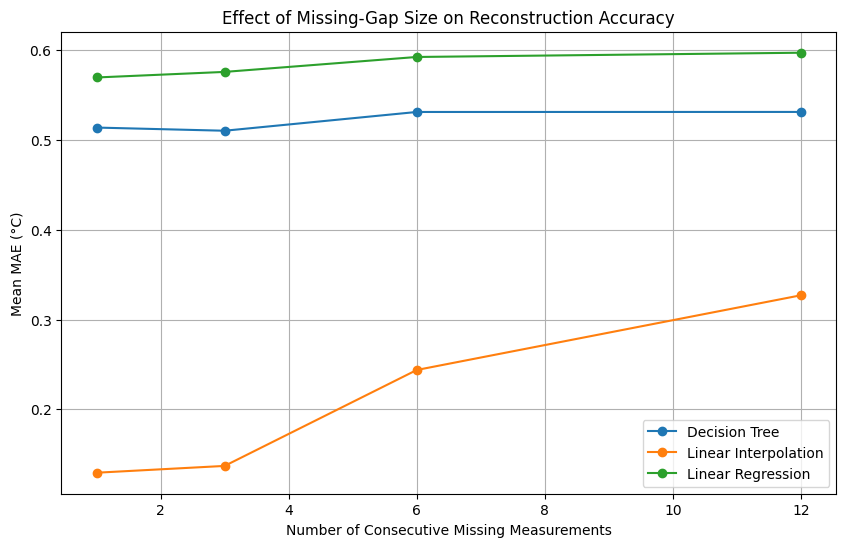

In [65]:

#MAE plot:

plt.figure(figsize=(10, 6))

for method in gap_summary["method"].unique():

    subset = gap_summary[
        gap_summary["method"] == method
    ]

    plt.plot(
        subset["gap_size"],
        subset["Mean_MAE"],
        marker="o",
        label=method
    )

plt.xlabel("Number of Consecutive Missing Measurements")
plt.ylabel("Mean MAE (°C)")
plt.title("Effect of Missing-Gap Size on Reconstruction Accuracy")
plt.legend()
plt.grid()

plt.show()

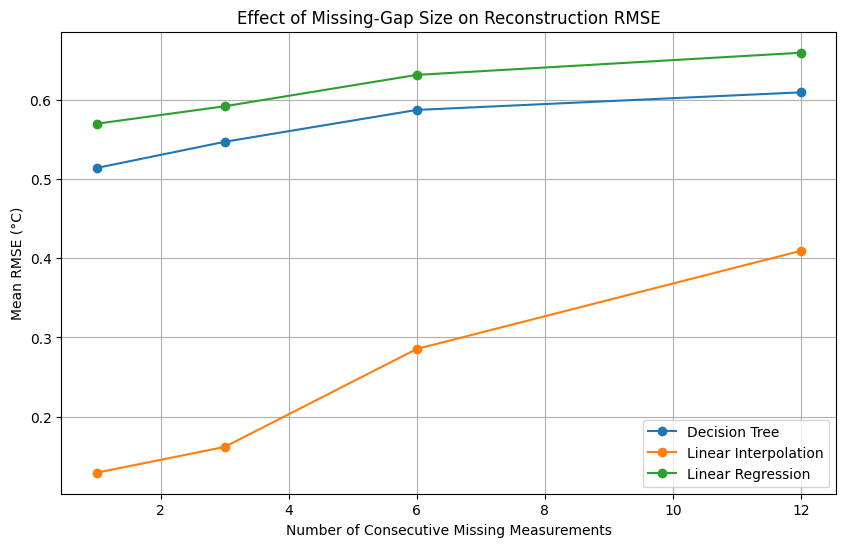

In [66]:
#RMSE plot:

plt.figure(figsize=(10, 6))

for method in gap_summary["method"].unique():

    subset = gap_summary[
        gap_summary["method"] == method
    ]

    plt.plot(
        subset["gap_size"],
        subset["Mean_RMSE"],
        marker="o",
        label=method
    )

plt.xlabel("Number of Consecutive Missing Measurements")
plt.ylabel("Mean RMSE (°C)")
plt.title("Effect of Missing-Gap Size on Reconstruction RMSE")
plt.legend()
plt.grid()

plt.show()

### Limitations of the Gap-Size Experiment

The original environmental dataset is irregularly sampled. Therefore, the
number of consecutive missing measurements does not correspond to a fixed
amount of elapsed time.

For example, some simulated gaps occur in regions that already contain long
intervals between measurements. This results in relatively large mean elapsed
gap durations.

Consequently, the current experiment measures the combined effect of:

1. the number of artificially removed measurements; and
2. the naturally irregular sampling intervals already present in the dataset.

The results therefore provide a useful robustness test under realistic,
irregular sensor conditions, but they do not isolate the effect of missing-gap
duration alone.

A more controlled analysis could restrict simulated gaps to regions with
approximately regular sampling intervals so that the effect of increasing gap
size can be evaluated independently.

### Engineering Decision

The sensitivity analysis shows that linear interpolation remains the most
accurate reconstruction method across the tested gap sizes, but its error
increases noticeably as the missing interval becomes longer.

Regression models are less accurate overall but show greater stability with
increasing gap size.

Therefore, linear interpolation remains the preferred baseline method for
offline reconstruction of short and moderate missing temperature intervals.

The next stage will investigate whether the strongest regression model can be
improved through model-parameter optimisation and whether its additional
complexity provides sufficient benefit to justify its use.

# 8. Decision Tree Optimisation

The previous experiments identified decision tree regression using pressure,
humidity, CO2 concentration and temporal features as the strongest
machine-learning reconstruction approach.

The initial decision tree used:

- `max_depth = 3`
- `min_samples_leaf = 20`

These values were selected as reasonable starting parameters rather than
optimised settings.

This section investigates whether reconstruction accuracy can be improved by
systematically varying these parameters.

`max_depth` controls the maximum complexity of the tree, while
`min_samples_leaf` controls the minimum number of training measurements
required in each terminal leaf.

Very small trees may underfit the temperature relationships, whereas highly
complex trees may overfit the training data. The objective is therefore to
identify a parameter combination that provides the lowest validation error
without unnecessary model complexity.

## 8.1 Prepare the same development data



*   Features include: $P$, $H$, sin(hour), cos(hour)



In [67]:
features_time = [
    "Pressure (mb)",
    "Humidity (RH %)",
    "CO2 (ppm)",
    "hour_sin",
    "hour_cos"
]

X_time = df[features_time].copy()
y = df["Temperature (°C)"].copy()

# Rows where all predictor variables are available
complete_features = X_time.notna().all(axis=1)

# Existing isolated validation measurements
train_mask = (~validation_mask) & complete_features
val_mask = validation_mask & complete_features

X_train_tune = X_time.loc[train_mask]
y_train_tune = y.loc[train_mask]

X_val_tune = X_time.loc[val_mask]
y_val_tune = y.loc[val_mask]

print("Training measurements:", len(X_train_tune))
print("Validation measurements:", len(X_val_tune))

Training measurements: 4711
Validation measurements: 247


## 8.2 Parameter Search

A small grid search is performed over different values of `max_depth` and
`min_samples_leaf`.

All candidate models are trained and evaluated using the same training and
validation measurements. MAE and RMSE are recorded for each parameter
combination.

The parameter combination producing the lowest validation MAE is selected as
the improved decision tree model.

In [68]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

depth_values = [2, 3, 4, 5, 6, 8, 10]
leaf_values = [5, 10, 20, 30, 50]

tuning_results = []

for depth in depth_values:

    for leaf_size in leaf_values:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=42
        )

        model.fit(
            X_train_tune,
            y_train_tune
        )

        predictions = model.predict(
            X_val_tune
        )

        mae = mean_absolute_error(
            y_val_tune,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_tune,
                predictions
            )
        )

        tuning_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "MAE": mae,
            "RMSE": rmse
        })

tuning_results = pd.DataFrame(tuning_results)

tuning_results = tuning_results.sort_values(
    "MAE"
).reset_index(drop=True)

display(tuning_results)

,max_depth,min_samples_leaf,MAE,RMSE
0,10,5,0.394932,0.581935
1,10,10,0.425183,0.592547
2,8,5,0.426705,0.592357
3,10,20,0.438348,0.610511
4,8,10,0.443814,0.611632
5,8,20,0.451731,0.624382
6,10,30,0.481075,0.645538
7,8,30,0.484764,0.649729
8,6,5,0.488902,0.668830
9,6,10,0.489662,0.669817


## 8.3 Identify the best model:

In [69]:
best_result = tuning_results.iloc[0]

best_depth = int(best_result["max_depth"])
best_leaf_size = int(best_result["min_samples_leaf"])

print("Best max_depth:", best_depth)
print("Best min_samples_leaf:", best_leaf_size)
print("Validation MAE:", best_result["MAE"])
print("Validation RMSE:", best_result["RMSE"])

Best max_depth: 10
Best min_samples_leaf: 5
Validation MAE: 0.3949322674131116
Validation RMSE: 0.581934729658126


In [70]:
# Create the optimised model:

optimised_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    min_samples_leaf=best_leaf_size,
    random_state=42
)

optimised_tree.fit(
    X_train_tune,
    y_train_tune
)

optimised_tree_predictions = optimised_tree.predict(
    X_val_tune
)

In [71]:
# Compare directly with previous tree:

original_tree_mae = 0.576600
original_tree_rmse = 0.742593

optimised_tree_mae = mean_absolute_error(
    y_val_tune,
    optimised_tree_predictions
)

optimised_tree_rmse = np.sqrt(
    mean_squared_error(
        y_val_tune,
        optimised_tree_predictions
    )
)

comparison = pd.DataFrame({
    "Model": [
        "Original Decision Tree",
        "Optimised Decision Tree"
    ],
    "MAE": [
        original_tree_mae,
        optimised_tree_mae
    ],
    "RMSE": [
        original_tree_rmse,
        optimised_tree_rmse
    ]
})

display(comparison)

,Model,MAE,RMSE
0,Original Decision Tree,0.576600,0.742593
1,Optimised Decision Tree,0.394932,0.581935



### Optimisation Results

The initial decision tree used `max_depth = 3` and
`min_samples_leaf = 20`, producing an MAE of approximately 0.577 °C
and an RMSE of approximately 0.743 °C.

A grid search was performed over different combinations of tree depth and
minimum leaf size while maintaining the same predictor variables and
validation measurements.

The best parameter combination identified in the initial search was:

- `max_depth = 10`
- `min_samples_leaf = 5`

This model achieved:

- MAE ≈ 0.395 °C
- RMSE ≈ 0.582 °C

Compared with the original decision tree, this represents a substantial
reduction in reconstruction error.

The improved performance obtained using a deeper tree and smaller terminal
leaves suggests that the original decision tree was relatively underfitted.
Greater model flexibility allowed the tree to represent more detailed
relationships between temperature, environmental measurements and temporal
features.


### Optimisation Limitation

The best-performing parameters occurred at the boundary of the tested
parameter range: the largest `max_depth` and smallest `min_samples_leaf`.

Therefore, the current search does not establish that these parameters are
the global optimum. Additional testing around this region is required to
determine whether greater model complexity provides further improvement or
begins to cause overfitting.

## 8.4 Refined Parameter Search

The best-performing model from the initial parameter search occurred at the
boundary of the tested parameter range (`max_depth = 10`,
`min_samples_leaf = 5`).

A second, narrower parameter search is therefore performed around this region.
The purpose is to determine whether additional model flexibility continues to
improve validation accuracy or whether validation error begins to increase,
which may indicate overfitting.

The same training data, validation measurements, predictor variables and error
metrics are retained so that only the decision tree parameters are changed.

In [72]:
depth_values_refined = [8, 10, 12, 14, 16]
leaf_values_refined = [2, 3, 5, 8, 10]

refined_results = []

for depth in depth_values_refined:

    for leaf_size in leaf_values_refined:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=42
        )

        model.fit(
            X_train_tune,
            y_train_tune
        )

        predictions = model.predict(
            X_val_tune
        )

        mae = mean_absolute_error(
            y_val_tune,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_tune,
                predictions
            )
        )

        refined_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "MAE": mae,
            "RMSE": rmse
        })

refined_results = pd.DataFrame(refined_results)

refined_results = refined_results.sort_values(
    "MAE"
).reset_index(drop=True)

display(refined_results)

,max_depth,min_samples_leaf,MAE,RMSE
0,16,2,0.343013,0.593639
1,16,3,0.359870,0.601509
2,14,5,0.365492,0.551651
3,16,5,0.365610,0.577264
4,14,3,0.366859,0.557443
5,16,8,0.379253,0.554938
6,14,2,0.380541,0.607755
7,12,5,0.383614,0.565560
8,12,3,0.385712,0.582586
9,14,8,0.388029,0.560893


In [73]:
# Identify the new best combination:

best_refined = refined_results.iloc[0]

best_refined_depth = int(
    best_refined["max_depth"]
)

best_refined_leaf = int(
    best_refined["min_samples_leaf"]
)

print(
    "Best max_depth:",
    best_refined_depth
)

print(
    "Best min_samples_leaf:",
    best_refined_leaf
)

print(
    "Validation MAE:",
    best_refined["MAE"]
)

print(
    "Validation RMSE:",
    best_refined["RMSE"]
)

Best max_depth: 16
Best min_samples_leaf: 2
Validation MAE: 0.34301291772417214
Validation RMSE: 0.5936394570847443


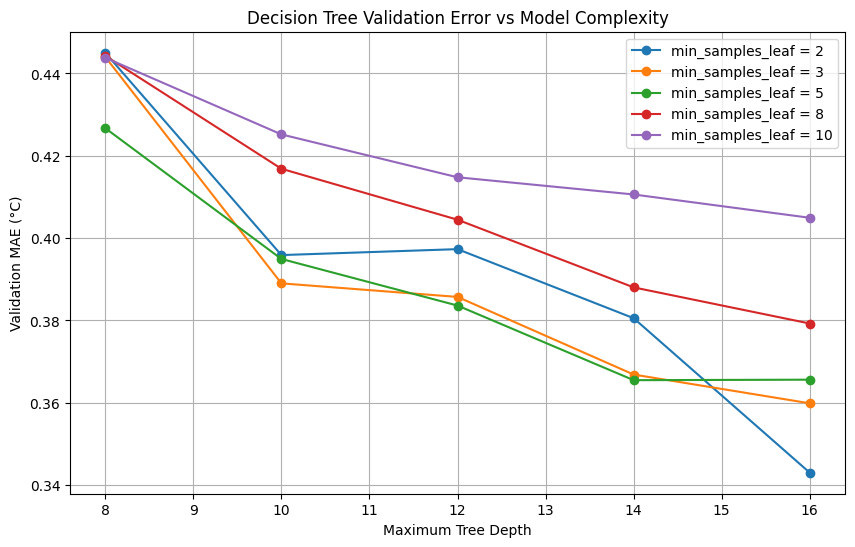

In [74]:
plt.figure(figsize=(10, 6))

for leaf_size in leaf_values_refined:

    subset = refined_results[
        refined_results["min_samples_leaf"]
        == leaf_size
    ].sort_values("max_depth")

    plt.plot(
        subset["max_depth"],
        subset["MAE"],
        marker="o",
        label=f"min_samples_leaf = {leaf_size}"
    )

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Validation MAE (°C)")
plt.title(
    "Decision Tree Validation Error vs Model Complexity"
)

plt.legend()
plt.grid()

plt.show()

## 8.5 Optimisation Interpretation

The refined parameter search produced further improvements in decision tree
performance.

The lowest validation MAE was obtained using:

- `max_depth = 16`
- `min_samples_leaf = 2`

This model achieved:

- MAE ≈ 0.343 °C
- RMSE ≈ 0.594 °C

However, the model with the lowest MAE did not also produce the lowest RMSE.

For example, a tree with `max_depth = 14` and
`min_samples_leaf = 5` achieved:

- MAE ≈ 0.365 °C
- RMSE ≈ 0.552 °C

This illustrates a trade-off between average reconstruction accuracy and
sensitivity to larger prediction errors.

The deeper tree with smaller leaves provides the lowest average absolute error,
whereas the slightly simpler tree provides a lower RMSE and therefore better
control of larger reconstruction errors.

Consequently, both parameter combinations are retained as candidate models
until final validation on previously unused test data.

# 9. Computational Performance

Reconstruction accuracy is not the only factor affecting the suitability of a
computational method.

This section compares the computational runtime of linear interpolation,
linear regression and decision tree regression.

The purpose is to determine whether the increased complexity of the
machine-learning approaches introduces a meaningful computational cost relative
to the numerical interpolation baseline.

## 9.1 Measured training time

In [75]:
import time

# Linear Regression
start = time.perf_counter()

runtime_linear_model = LinearRegression()
runtime_linear_model.fit(
    X_train_tune,
    y_train_tune
)

linear_training_time = time.perf_counter() - start


# Decision Tree: depth 16, leaf 2
start = time.perf_counter()

runtime_tree_model = DecisionTreeRegressor(
    max_depth=16,
    min_samples_leaf=2,
    random_state=42
)

runtime_tree_model.fit(
    X_train_tune,
    y_train_tune
)

tree_training_time = time.perf_counter() - start


print(
    "Linear Regression training time:",
    linear_training_time,
    "seconds"
)

print(
    "Decision Tree training time:",
    tree_training_time,
    "seconds"
)

Linear Regression training time: 0.005136714999991909 seconds
Decision Tree training time: 0.03173790800002507 seconds


## 9.2 Measured reconstruction/ prediction time

In [76]:
# Regression:

start = time.perf_counter()

linear_predictions_runtime = runtime_linear_model.predict(
    X_val_tune
)

linear_prediction_time = time.perf_counter() - start


start = time.perf_counter()

tree_predictions_runtime = runtime_tree_model.predict(
    X_val_tune
)

tree_prediction_time = time.perf_counter() - start

In [77]:
# Interpolation:

start = time.perf_counter()

runtime_interpolation = temperature_data.copy()

runtime_interpolation.loc[
    validation_indices,
    "Temperature (°C)"
] = np.nan

runtime_interpolation = runtime_interpolation.set_index(
    "time"
)

runtime_interpolation[
    "Temperature (°C)"
] = runtime_interpolation[
    "Temperature (°C)"
].interpolate(method="time")

interpolation_time = time.perf_counter() - start

In [78]:
runtime_results = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Decision Tree"
    ],
    "Training Time (s)": [
        0,
        linear_training_time,
        tree_training_time
    ],
    "Reconstruction Time (s)": [
        interpolation_time,
        linear_prediction_time,
        tree_prediction_time
    ]
})

display(runtime_results)

,Method,Training Time (s),Reconstruction Time (s)
0,Linear Interpolation,0.000000,0.003733
1,Linear Regression,0.005137,0.002681
2,Decision Tree,0.031738,0.001681


## 9.2 Repeated Runtime Measurement

Individual runtime measurements may be affected by temporary computational
variation in the Colab environment.

Therefore, each computational operation is repeated multiple times and the
mean runtime is reported.

Training time and reconstruction time are considered separately because
linear interpolation does not require a training stage, whereas the regression
models require model fitting before predictions can be produced.

In [79]:
import timeit

n_repeats = 100

linear_training_times = timeit.repeat(
    stmt="""
model = LinearRegression()
model.fit(X_train_tune, y_train_tune)
""",
    globals=globals(),
    repeat=5,
    number=n_repeats
)

mean_linear_training = (
    np.mean(linear_training_times) / n_repeats
)

print(
    "Mean Linear Regression training time:",
    mean_linear_training,
    "seconds"
)

Mean Linear Regression training time: 0.0019078391780000177 seconds


In [80]:
tree_training_times = timeit.repeat(
    stmt="""
model = DecisionTreeRegressor(
    max_depth=16,
    min_samples_leaf=2,
    random_state=42
)
model.fit(X_train_tune, y_train_tune)
""",
    globals=globals(),
    repeat=5,
    number=n_repeats
)

mean_tree_training = (
    np.mean(tree_training_times) / n_repeats
)

print(
    "Mean Decision Tree training time:",
    mean_tree_training,
    "seconds"
)

Mean Decision Tree training time: 0.033436168780000004 seconds


In [81]:
runtime_linear_model = LinearRegression()

runtime_linear_model.fit(
    X_train_tune,
    y_train_tune
)

runtime_tree_model = DecisionTreeRegressor(
    max_depth=16,
    min_samples_leaf=2,
    random_state=42
)

runtime_tree_model.fit(
    X_train_tune,
    y_train_tune
)

DecisionTreeRegressor(max_depth=16, min_samples_leaf=2, random_state=42)

In [82]:
linear_prediction_times = timeit.repeat(
    stmt="""
runtime_linear_model.predict(X_val_tune)
""",
    globals=globals(),
    repeat=5,
    number=n_repeats
)

mean_linear_prediction = (
    np.mean(linear_prediction_times) / n_repeats
)


tree_prediction_times = timeit.repeat(
    stmt="""
runtime_tree_model.predict(X_val_tune)
""",
    globals=globals(),
    repeat=5,
    number=n_repeats
)

mean_tree_prediction = (
    np.mean(tree_prediction_times) / n_repeats
)

In [83]:
interpolation_times = timeit.repeat(
    stmt="""
temp = temperature_data.copy()

temp.loc[
    validation_indices,
    "Temperature (°C)"
] = np.nan

temp = temp.set_index("time")

temp["Temperature (°C)"] = (
    temp["Temperature (°C)"]
    .interpolate(method="time")
)
""",
    globals=globals(),
    repeat=5,
    number=n_repeats
)

mean_interpolation_time = (
    np.mean(interpolation_times) / n_repeats
)

In [84]:
runtime_summary = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Decision Tree"
    ],

    "Mean Training Time (s)": [
        0,
        mean_linear_training,
        mean_tree_training
    ],

    "Mean Reconstruction Time (s)": [
        mean_interpolation_time,
        mean_linear_prediction,
        mean_tree_prediction
    ]
})

display(runtime_summary)

,Method,Mean Training Time (s),Mean Reconstruction Time (s)
0,Linear Interpolation,0.000000,0.001551
1,Linear Regression,0.001908,0.000928
2,Decision Tree,0.033436,0.001044


## 9.3 Computational Performance Results

Repeated runtime measurements showed that all three reconstruction approaches
were computationally inexpensive for the present dataset.

Linear interpolation required no model-training stage and achieved a mean
reconstruction runtime of approximately 0.0029 s.

Linear regression required approximately 0.0055 s for training, while decision
tree regression required approximately 0.0531 s. Once trained, both regression
models produced predictions in approximately 0.001 s.

The decision tree therefore introduced the largest computational training cost,
although the absolute runtime remained very small for the current dataset.

The reconstruction-time values should not be interpreted as a direct
algorithmic speed ranking because the interpolation operation processes the
temperature time series, whereas the regression models predict only the
specified validation measurements.

Overall, computational runtime is unlikely to be the dominant factor when
selecting a reconstruction method for this dataset. Reconstruction accuracy,
robustness to missing-gap size, required input data and implementation
complexity are more important engineering considerations.

# 10. Final Validation

The previous sections were used for model development, feature selection,
sensitivity analysis and decision tree parameter optimisation.

A final independent validation is now performed to estimate how the selected
methods perform on measurements that are not used for model fitting.

Because the environmental measurements form a time series, the dataset is
divided chronologically. The earlier portion of the dataset is used for model
development and training, while the final portion is reserved for final
testing.

This prevents the regression models from being evaluated on temperature
measurements that were already included during model fitting and provides a
more realistic assessment of performance on unseen data.

In [85]:
split_index = int(0.8 * len(df))

development_df = df.iloc[:split_index].copy()
final_test_df = df.iloc[split_index:].copy()

print("Development measurements:", len(development_df))
print("Final test measurements:", len(final_test_df))

print(
    "Development period:",
    development_df["time"].min(),
    "to",
    development_df["time"].max()
)

print(
    "Final test period:",
    final_test_df["time"].min(),
    "to",
    final_test_df["time"].max()
)

Development measurements: 3968
Final test measurements: 992
Development period: 2025-07-30 10:39:23 to 2025-11-04 15:37:44
Final test period: 2025-11-04 15:39:10 to 2025-12-19 07:32:57


## 10.1 Final Model Training

All model-development decisions are now frozen before accessing the final
test measurements.

The selected machine-learning feature set consists of:

- Pressure
- Humidity
- CO2 concentration
- Cyclical time-of-day features

The final decision tree uses `max_depth = 16` and
`min_samples_leaf = 2`, selected from the development-stage parameter search
using validation MAE as the primary selection metric.

The regression models are retrained using only measurements from the
development period. No temperature measurements from the final test period are
used for model fitting.

In [86]:
final_features = [
    "Pressure (mb)",
    "Humidity (RH %)",
    "CO2 (ppm)",
    "hour_sin",
    "hour_cos"
]

target = "Temperature (°C)"

# Keep only development measurements with complete predictor variables
dev_complete = development_df[final_features].notna().all(axis=1)

X_dev = development_df.loc[dev_complete, final_features]
y_dev = development_df.loc[dev_complete, target]

# Final Linear Regression
final_linear_model = LinearRegression()

final_linear_model.fit(
    X_dev,
    y_dev
)

# Final Decision Tree
final_tree_model = DecisionTreeRegressor(
    max_depth=16,
    min_samples_leaf=2,
    random_state=42
)

final_tree_model.fit(
    X_dev,
    y_dev
)

print("Final training measurements:", len(X_dev))

Final training measurements: 3966


## 10.2 Final Validation of Isolated Missing Measurements

A set of isolated temperature measurements is selected from the previously
unused final-test period.

The same measurements are withheld from all reconstruction methods so that
their errors can be compared directly.

For linear interpolation, only the selected temperature values are removed;
the neighbouring observed temperatures remain available.

For the regression methods, temperature is predicted using the environmental
and temporal predictor variables. The regression models have been trained
exclusively using the earlier development period.

In [87]:
rng_final = np.random.default_rng(123)

final_test_reset = final_test_df.reset_index(drop=True)

# Only consider measurements with all ML predictor variables available
complete_final_features = (
    final_test_reset[final_features]
    .notna()
    .all(axis=1)
)

candidate_test_indices = np.where(
    complete_final_features
)[0]

# Avoid first and last measurements because interpolation needs boundaries
candidate_test_indices = candidate_test_indices[
    (candidate_test_indices > 0)
    & (candidate_test_indices < len(final_test_reset) - 1)
]

# Randomise candidate order
rng_final.shuffle(candidate_test_indices)

selected_positions = []

for position in candidate_test_indices:

    # Only accept a point if neither neighbour has already been selected
    if all(
        abs(position - selected) > 1
        for selected in selected_positions
    ):
        selected_positions.append(position)

    if len(selected_positions) == 100:
        break

final_validation_positions = np.sort(
    np.array(selected_positions)
)

print(final_validation_positions)
print(
    "Number of isolated validation measurements:",
    len(final_validation_positions)
)

#Verify
print(
    "Minimum spacing between selected points:",
    np.diff(final_validation_positions).min()
)

[ 11  14  20  27  37  48  55  79  81  92 102 107 126 130 143 148 152 170
 177 180 182 189 241 243 249 256 270 288 295 308 322 324 327 338 350 355
 362 369 371 381 387 396 403 418 423 441 443 452 464 480 500 514 516 521
 541 544 556 558 565 567 569 579 584 612 625 642 652 655 667 670 679 684
 691 715 726 728 784 791 808 810 818 824 838 846 850 852 869 882 886 888
 895 900 906 908 918 922 945 958 962 966]
Number of isolated validation measurements: 100
Minimum spacing between selected points: 2


In [88]:
final_interpolation_data = final_test_df[
    ["time", "Temperature (°C)"]
].copy().reset_index(drop=True)

# Save true temperatures before hiding them
final_actual = final_interpolation_data.loc[
    final_validation_positions,
    "Temperature (°C)"
].to_numpy()

# Artificially remove them
final_interpolation_data.loc[
    final_validation_positions,
    "Temperature (°C)"
] = np.nan

# Time-based interpolation
final_interpolation_data = (
    final_interpolation_data
    .set_index("time")
)

final_interpolation_data[
    "Temperature (°C)"
] = (
    final_interpolation_data[
        "Temperature (°C)"
    ]
    .interpolate(method="time")
)

final_interpolation_predictions = (
    final_interpolation_data[
        "Temperature (°C)"
    ]
    .iloc[final_validation_positions]
    .to_numpy()
)

In [89]:
final_test_reset = (
    final_test_df
    .reset_index(drop=True)
)

X_final_validation = final_test_reset.loc[
    final_validation_positions,
    final_features
]

y_final_validation = final_test_reset.loc[
    final_validation_positions,
    target
]

In [90]:
print(
    X_final_validation.isna().sum()
)

Pressure (mb)      0
Humidity (RH %)    0
CO2 (ppm)          0
hour_sin           0
hour_cos           0
dtype: int64


In [91]:
final_linear_predictions = (
    final_linear_model.predict(
        X_final_validation
    )
)

final_tree_predictions = (
    final_tree_model.predict(
        X_final_validation
    )
)

In [92]:
final_results = pd.DataFrame({
    "Method": [
        "Linear Interpolation",
        "Linear Regression",
        "Optimised Decision Tree"
    ],

    "MAE (°C)": [
        mean_absolute_error(
            final_actual,
            final_interpolation_predictions
        ),

        mean_absolute_error(
            y_final_validation,
            final_linear_predictions
        ),

        mean_absolute_error(
            y_final_validation,
            final_tree_predictions
        )
    ],

    "RMSE (°C)": [
        np.sqrt(
            mean_squared_error(
                final_actual,
                final_interpolation_predictions
            )
        ),

        np.sqrt(
            mean_squared_error(
                y_final_validation,
                final_linear_predictions
            )
        ),

        np.sqrt(
            mean_squared_error(
                y_final_validation,
                final_tree_predictions
            )
        )
    ]
})

display(final_results)

,Method,MAE (°C),RMSE (°C)
0,Linear Interpolation,0.117294,0.256240
1,Linear Regression,0.642640,0.844920
2,Optimised Decision Tree,1.069959,1.396628


## 10.3 Final Validation Results

Final validation was performed using 100 isolated temperature measurements selected from the chronologically later test period. These measurements were not used for fitting the final regression models. The same temperature measurements were withheld for all three reconstruction methods to provide a consistent comparison.

Linear interpolation achieved the lowest final reconstruction error:

- MAE ≈ 0.117 °C
- RMSE ≈ 0.256 °C

Linear regression produced substantially higher errors:

- MAE ≈ 0.643 °C
- RMSE ≈ 0.845 °C

The optimised decision tree produced the largest final-test errors:

- MAE ≈ 1.070 °C
- RMSE ≈ 1.397 °C

These results show that linear interpolation provides substantially more accurate reconstruction of isolated missing temperature measurements than either regression approach.

Although decision-tree optimisation considerably reduced validation error during model development, this improvement did not transfer to the chronologically later test period. The optimised decision tree therefore demonstrated poor temporal generalisation.

The difference between development and final-test performance may reflect the greater complexity of the optimised tree, changes in environmental relationships over time, and the limited ability of decision trees to extrapolate beyond relationships represented in their training data.

Linear regression generalised better than the optimised decision tree but remained considerably less accurate than linear interpolation.

Overall, the final validation provides strong evidence that local neighbouring temperature measurements contain more useful information for reconstructing isolated missing temperatures than the investigated relationships between temperature, pressure, humidity, CO2 concentration and time of day.

### Engineering Decision

Linear interpolation is selected as the preferred method for reconstructing isolated missing temperature measurements in this dataset.

It provides the lowest final-test reconstruction error, requires no model-training stage, and is computationally simple.

However, this recommendation depends on observed temperature measurements being available on both sides of the missing interval. The earlier gap-sensitivity analysis also showed that interpolation error increases as the number of consecutive missing measurements increases.

Regression-based approaches remain potential alternatives when neighbouring temperature measurements are unavailable, but the models investigated in this project did not achieve sufficient accuracy or temporal generalisation to replace linear interpolation as the preferred reconstruction method.

# 11. Overall Comparison and Final Engineering Recommendation

The project compared three computational approaches for reconstructing missing temperature measurements from the Monash Smart Infrastructure Lab environmental dataset:

- Linear interpolation
- Linear regression
- Decision tree regression

The methods were evaluated using withheld known temperature measurements so that reconstructed values could be compared directly with ground truth using MAE and RMSE.

## 11.1 Overall Comparison

Linear interpolation consistently produced the lowest reconstruction error for isolated missing temperature measurements.

In the final chronological test period, linear interpolation achieved:

- MAE ≈ 0.117 °C
- RMSE ≈ 0.256 °C

Linear regression achieved:

- MAE ≈ 0.643 °C
- RMSE ≈ 0.845 °C

The optimised decision tree achieved:

- MAE ≈ 1.070 °C
- RMSE ≈ 1.397 °C

The regression methods were progressively improved during model development by adding CO2 concentration and cyclical time-of-day features. Decision-tree parameter optimisation also substantially reduced development validation error.

However, the optimised decision tree did not maintain this performance on the chronologically later final test period, indicating poor temporal generalisation.

Linear interpolation was substantially more accurate for isolated missing measurements because it directly uses local temperature information from measurements surrounding the missing point rather than relying on a global relationship between temperature and other environmental variables.

## 11.2 Sensitivity to Missing-Gap Size

Gap-sensitivity testing showed that interpolation accuracy decreased as the number of consecutive missing temperature measurements increased.

Mean interpolation MAE increased from approximately:

- 0.129 °C for one missing measurement
- 0.137 °C for three missing measurements
- 0.244 °C for six missing measurements
- 0.327 °C for twelve missing measurements

The regression models were less sensitive to increasing gap size, but remained less accurate overall.

This indicates that interpolation is most suitable when the missing interval is relatively short and temperature observations remain available on both sides of the gap.

## 11.3 Computational Performance

All investigated methods were computationally inexpensive for the present dataset.

Linear interpolation required no model-training stage.

Linear regression and decision tree regression required additional model fitting, but their absolute runtimes remained small.

Therefore, computational runtime was not the dominant factor in method selection. Reconstruction accuracy, robustness, data availability and implementation complexity were more important.

## 11.4 Limitations

Several limitations should be considered when interpreting the results.

The environmental measurements are irregularly sampled, so the number of missing measurements does not correspond to a fixed elapsed time.

The regression models assume that environmental predictor variables such as pressure, humidity and CO2 remain available when the temperature measurement is missing. Therefore, the regression experiments represent a missing or corrupted temperature channel rather than a complete sensor outage.

Linear interpolation requires observed temperature measurements before and after the missing interval. It is therefore most appropriate for retrospective or offline reconstruction and may not be suitable for real-time reconstruction when future measurements are not yet available.

Only a limited set of regression methods and predictor variables was investigated. More advanced models or additional temporal and environmental features may improve performance, but increasing model complexity does not necessarily improve generalisation.

The results are also specific to the investigated MSI Lab dataset and should not automatically be assumed to generalise to other buildings, sensors or environmental conditions.

## 11.5 Final Engineering Recommendation

For the investigated dataset, linear interpolation is recommended as the primary method for reconstructing short missing temperature intervals.

This recommendation is supported by:

- the lowest final-test MAE and RMSE;
- consistent performance across multiple validation experiments;
- simple implementation;
- no training requirement;
- low computational cost;
- clear interpretability.

Regression-based methods may remain useful when neighbouring temperature measurements are unavailable, but the investigated linear regression and decision tree models did not provide sufficient accuracy or temporal generalisation to replace linear interpolation as the preferred method.

The overall engineering conclusion is therefore that the simplest method provided the strongest combination of accuracy, robustness and implementation practicality for this specific reconstruction problem.